# SVM Implementation on Iris Dataset

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import svm, datasets
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report

In [6]:
df = pd.read_csv("/content/iris.csv")

## Feature Selection & Label Encoding

In [7]:
from sklearn.preprocessing import LabelEncoder

# Select only the first two features (sepal.length, sepal.width) for X and convert to NumPy array
X = df[['sepal.length', 'sepal.width']].values

# Encode the target variable 'variety' into numerical labels (y)
le = LabelEncoder()
y = le.fit_transform(df['variety']) # 'y' is now numerical and will be used for train_test_split

print("Original species labels:", le.classes_)
print("Encoded target labels (first 5):")
display(y[:5]) # Display the numerical 'y'

Original species labels: ['Setosa' 'Versicolor' 'Virginica']
Encoded target labels (first 5):


array([0, 0, 0, 0, 0])

## Split Dataset into Training and Testing

In [8]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 105 samples
Testing set size: 45 samples


## Linear SVM

In [9]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

linear_svm = SVC(
    kernel='linear',
    C=1
)

linear_svm.fit(X_train, y_train)

# Prediction
y_pred_linear = linear_svm.predict(X_test)

# Accuracy
linear_accuracy = accuracy_score(y_test, y_pred_linear)

print("\n========== LINEAR SVM ==========")
print("Accuracy:", linear_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_linear, target_names=le.classes_))


========== LINEAR SVM ==========
Accuracy: 0.7111111111111111

Classification Report:
              precision    recall  f1-score   support

      Setosa       0.94      1.00      0.97        15
  Versicolor       0.60      0.60      0.60        15
   Virginica       0.57      0.53      0.55        15

    accuracy                           0.71        45
   macro avg       0.70      0.71      0.71        45
weighted avg       0.70      0.71      0.71        45



## Plot Decision Boundary for Linear SVM

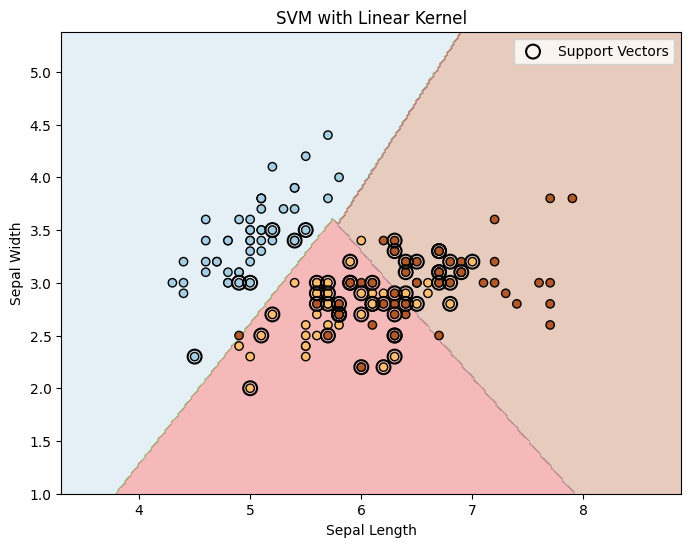

In [10]:
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

h = 0.02

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, h),
    np.arange(y_min, y_max, h)
)

Z = linear_svm.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3,
    cmap=plt.cm.Paired
)

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap=plt.cm.Paired,
    edgecolors='k'
)

# Highlight support vectors
plt.scatter(
    linear_svm.support_vectors_[:, 0],
    linear_svm.support_vectors_[:, 1],
    s=100,
    facecolors='none',
    edgecolors='black',
    linewidths=1.5,
    label='Support Vectors'
)

plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plt.title('SVM with Linear Kernel')
plt.legend()
plt.show()

## RBF SVM

In [11]:
rbf_svm = SVC(
    kernel='rbf',
    C=1,
    gamma='scale'
)

rbf_svm.fit(X_train, y_train)

y_pred_rbf = rbf_svm.predict(X_test)

rbf_accuracy = accuracy_score(y_test, y_pred_rbf)

print("\n========== RBF SVM ==========")
print("Accuracy:", rbf_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rbf, target_names=le.classes_))

print("\nConfusion Matrix:")
cm_rbf = confusion_matrix(y_test, y_pred_rbf)
display(pd.DataFrame(cm_rbf, index=le.classes_, columns=le.classes_))


========== RBF SVM ==========
Accuracy: 0.7333333333333333

Classification Report:
              precision    recall  f1-score   support

      Setosa       0.94      1.00      0.97        15
  Versicolor       0.62      0.67      0.65        15
   Virginica       0.62      0.53      0.57        15

    accuracy                           0.73        45
   macro avg       0.73      0.73      0.73        45
weighted avg       0.73      0.73      0.73        45


Confusion Matrix:


,Setosa,Versicolor,Virginica
Setosa,15,0,0
Versicolor,0,10,5
Virginica,1,6,8


## Plot Decision Boundary for RBF SVM

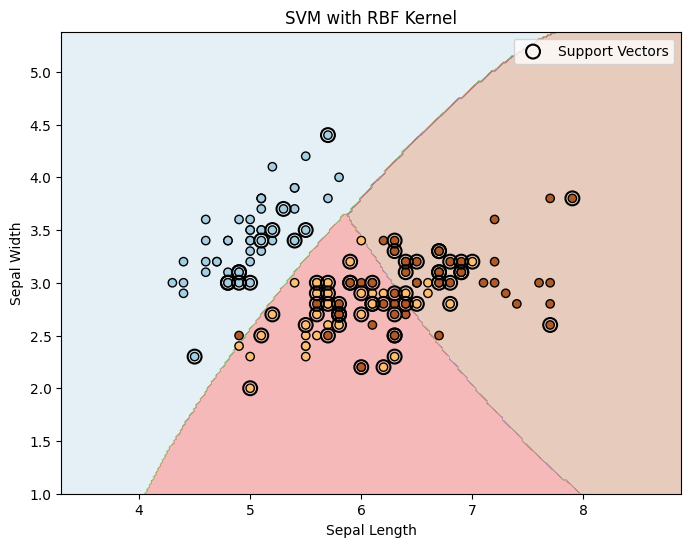

In [12]:
Z = rbf_svm.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3,
    cmap=plt.cm.Paired
)

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap=plt.cm.Paired,
    edgecolors='k'
)

# Highlight support vectors
plt.scatter(
    rbf_svm.support_vectors_[:, 0],
    rbf_svm.support_vectors_[:, 1],
    s=100,
    facecolors='none',
    edgecolors='black',
    linewidths=1.5,
    label='Support Vectors'
)

plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plt.title('SVM with RBF Kernel')
plt.legend()
plt.show()

## Compare Different Gamma Values

In [13]:
gamma_values = [0.01, 0.1, 1, 10, 100]

print("\n========== GAMMA COMPARISON ==========")

for gamma in gamma_values:
    model = SVC(
        kernel='rbf',
        C=1,
        gamma=gamma
    )
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    accuracy = accuracy_score(y_test, prediction)
    print("Gamma =", gamma, " | Accuracy =", accuracy)


========== GAMMA COMPARISON ==========
Gamma = 0.01  | Accuracy = 0.6222222222222222
Gamma = 0.1  | Accuracy = 0.7333333333333333
Gamma = 1  | Accuracy = 0.6888888888888889
Gamma = 10  | Accuracy = 0.7555555555555555
Gamma = 100  | Accuracy = 0.5777777777777777


## Cross Validation for RBF SVM

In [14]:
from sklearn.model_selection import cross_val_score

print("\n========== CROSS VALIDATION ==========")

for gamma in gamma_values:
    model = SVC(
        kernel='rbf',
        C=1,
        gamma=gamma
    )
    scores = cross_val_score(
        model,
        X,
        y,
        cv=5
    )
    print(
        "Gamma =", gamma,
        "| CV Accuracy =", round(scores.mean(), 4)
    )


========== CROSS VALIDATION ==========
Gamma = 0.01 | CV Accuracy = 0.7667
Gamma = 0.1 | CV Accuracy = 0.8133
Gamma = 1 | CV Accuracy = 0.8133
Gamma = 10 | CV Accuracy = 0.7933
Gamma = 100 | CV Accuracy = 0.6733


## Compare Different C Values

In [15]:
C_values = [0.01, 0.1, 1, 10, 100]

print("\n========== C PARAMETER COMPARISON ==========")

for C_val in C_values:
    model = SVC(
        kernel='rbf',
        C=C_val,
        gamma='scale'
    )
    scores = cross_val_score(
        model,
        X,
        y,
        cv=5
    )
    print(
        "C =", C_val,
        "| CV Accuracy =", round(scores.mean(), 4)
    )


========== C PARAMETER COMPARISON ==========
C = 0.01 | CV Accuracy = 0.7867
C = 0.1 | CV Accuracy = 0.7733
C = 1 | CV Accuracy = 0.82
C = 10 | CV Accuracy = 0.8133
C = 100 | CV Accuracy = 0.8133


## Final Comparison

In [16]:
print("\n========== FINAL RESULT ==========")

print("Linear SVM Accuracy :", round(linear_accuracy, 4))
print("RBF SVM Accuracy    :", round(rbf_accuracy, 4))


========== FINAL RESULT ==========
Linear SVM Accuracy : 0.7111
RBF SVM Accuracy    : 0.7333


Aim:
To implement Support Vector Machine (SVM) classification using Linear and RBF (Radial Basis Function) kernels on the Iris dataset and analyze the impact of hyperparameters (C and gamma) along with Cross-Validation.

Objective:
To classify Iris flower species using Support Vector Classifiers (SVC), visualize decision boundaries and support vectors, compare Linear vs. RBF kernel performance, and evaluate model generalization using 5-fold cross-validation.

Theory:
Support Vector Machine (SVM) is a powerful supervised machine learning algorithm used for classification and regression tasks. The primary objective of SVM is to find an optimal hyperplane in an N-dimensional feature space that distinctly separates data points belonging to different classes with the maximum possible margin.

Key Concepts in SVM:
1. Hyperplane: A decision boundary that separates different classes in the feature space. In 2D space, it is a line; in 3D space, it is a plane.
2. Support Vectors: The data points that lie closest to the decision boundary (hyperplane). These critical points directly determine the position and orientation of the hyperplane.
3. Margin: The perpendicular distance between the hyperplane and the nearest data points (support vectors) from either class. SVM aims to maximize this margin to achieve better generalization on unseen data.
4. Kernel Trick: When data is not linearly separable in its original space, SVM uses kernel functions to map input features into a higher-dimensional space where a linear hyperplane can separate them:
   - Linear Kernel: Suitable when data is linearly separable.
   - RBF (Radial Basis Function) Kernel: Maps data into an infinite-dimensional space to create non-linear decision boundaries.

Hyperparameters in SVM:
1. Regularization Parameter (C): Controls the trade-off between maximizing the margin and minimizing classification errors. A small C creates a wider margin with more tolerance for misclassifications (preventing overfitting), whereas a large C forces stricter classification with a narrower margin.
2. Gamma (gamma): Defines how far the influence of a single training example reaches in an RBF kernel. Low gamma means a large radius of influence (smoother boundary), while high gamma means a close radius of influence (tighter, more complex boundary around individual points).

Algorithm:
1. Load the Iris dataset and select the input features (sepal_length, sepal_width) and target class labels (species).
2. Encode the categorical target labels into numerical values using LabelEncoder.
3. Split the dataset into training (70%) and testing (30%) sets using stratified sampling.
4. Initialize and train a Linear SVM classifier (kernel='linear', C=1) on the training data.
5. Predict test labels, compute accuracy, print the classification report, and plot the linear decision boundary with highlighted support vectors.
6. Initialize and train an RBF SVM classifier (kernel='rbf', C=1, gamma='scale') on the training data.
7. Evaluate the RBF model using accuracy score, classification report, confusion matrix, and plot its non-linear decision boundary.
8. Perform hyperparameter tuning by comparing accuracy across multiple values of gamma ([0.01, 0.1, 1, 10, 100]) and C ([0.01, 0.1, 1, 10, 100]) using 5-fold Cross-Validation.
9. Compare the final test accuracies of the Linear SVM and RBF SVM models.

Formulas:
1. Equation of Hyperplane:
   w . x + b = 0
   (where w is the weight vector, x is the input feature vector, and b is the bias)

2. Margin Width:
   Margin = 2 / ||w||

3. Linear Kernel Function:
   K(x_i, x_j) = x_i . x_j

4. RBF (Gaussian) Kernel Function:
   K(x_i, x_j) = exp( -gamma * ||x_i - x_j||^2 )

5. Classification Accuracy:
   Accuracy = (TP + TN) / (TP + TN + FP + FN)


   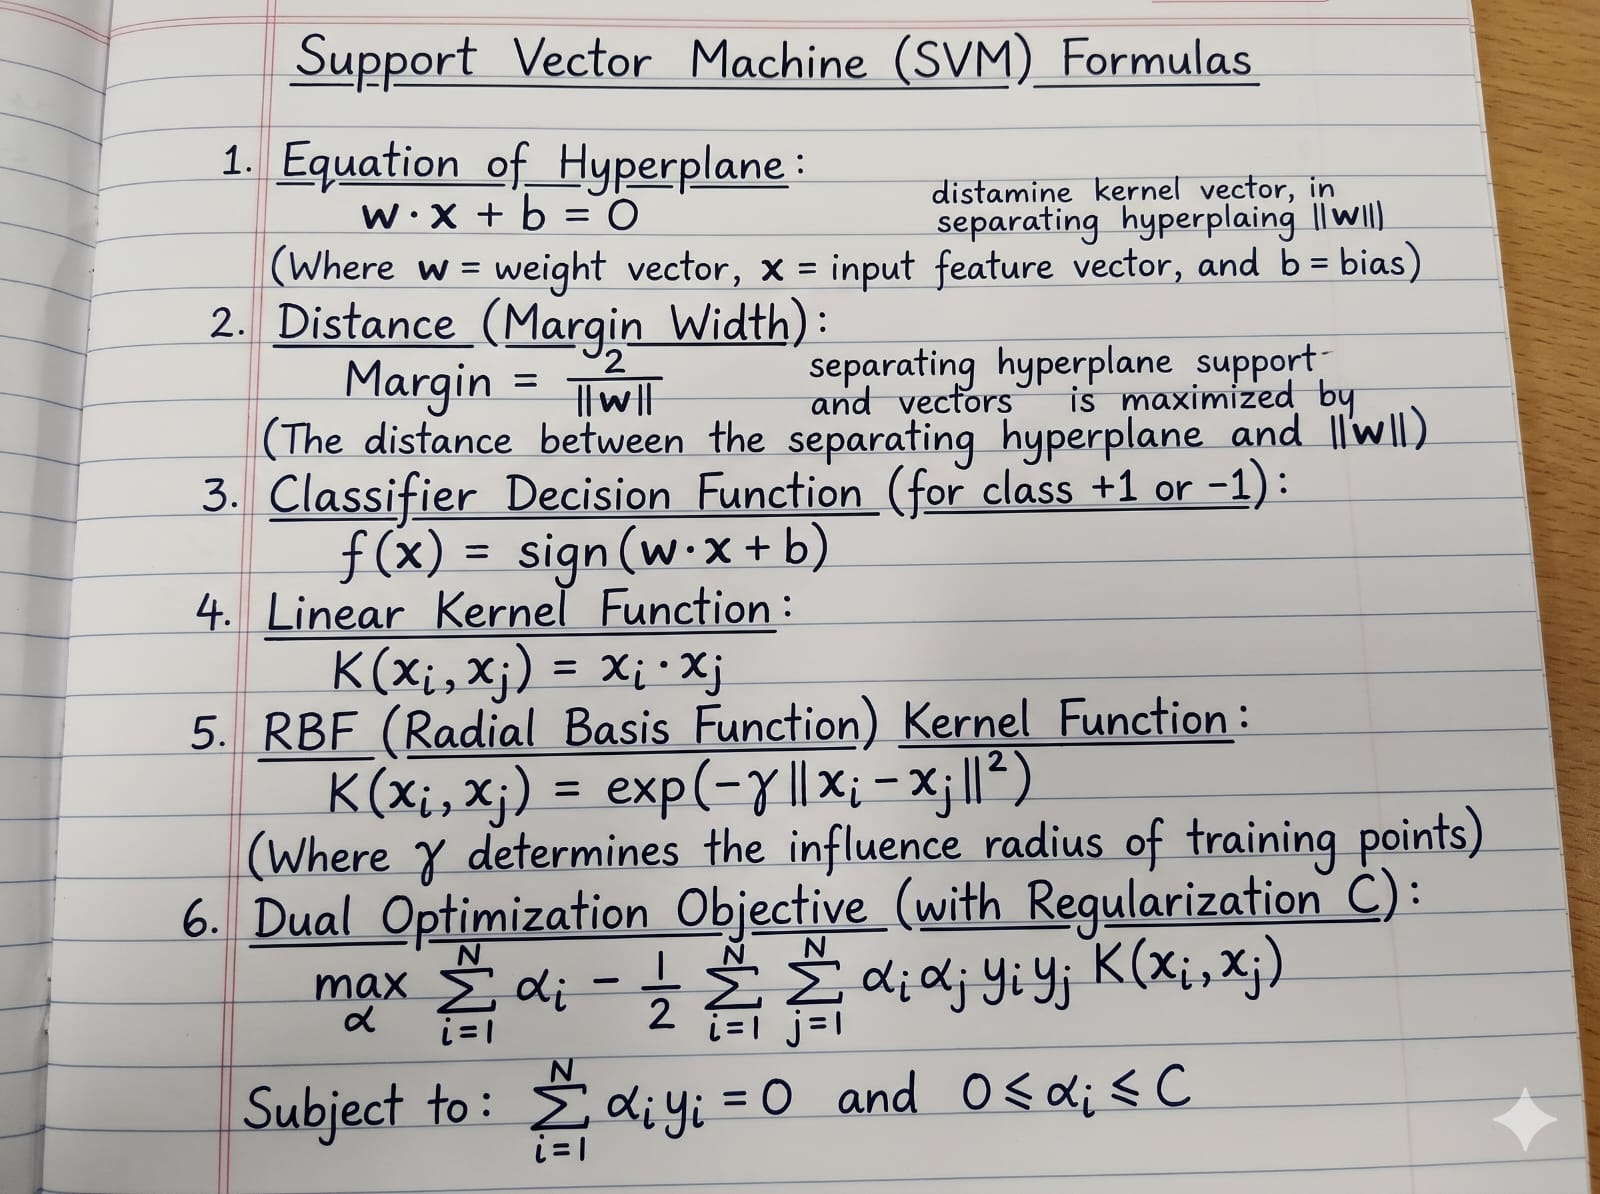
   

Difference Between Linear SVM and RBF SVM:
- Decision Boundary: Linear SVM creates a straight hyperplane; RBF SVM creates curved, non-linear boundaries.
- Computational Speed: Linear SVM is faster to train on large datasets; RBF SVM requires more computation due to kernel mapping.
- Hyperparameters: Linear SVM primarily depends on C; RBF SVM depends on both C and gamma.

Conclusion:
Hence, we have successfully studied and implemented Support Vector Machine (SVM) with Linear and RBF kernels in Python, visualized their decision boundaries and support vectors, and evaluated the effect of C and gamma hyperparameters using cross-validation.